In [1]:
# ============================================================
# EVALUATION EXPERIMENTS - corrected Brown WAWQI target (READ-ONLY)
# ============================================================
# Re-derives the SAME target and feature order as training by importing the
# shared wawqi module (no copied, drifting index code). Never writes to
# ../model/. Every model runs on ONE frozen split for comparability.

import os, sys
sys.path.insert(0, os.path.abspath(".."))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import sklearn
import shap

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              StackingRegressor)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import wawqi

RANDOM_STATE = 42
FEATURES = wawqi.PARAMS          # 7 parameters, authoritative order

df = pd.read_csv("../data/water_dataX.csv", encoding="latin1")
wqi_df, info = wawqi.clean_and_index(df)
print("raw ->", info["raw"], "| final N ->", info["final_n"], "| distinct WQI ->", wqi_df["WQI"].nunique())

raw -> 1991 | final N -> 1571 | distinct WQI -> 1566


In [2]:
# ============================================================
# VALIDITY GATE (structural, re-derived every run - no stale magic numbers)
# ============================================================
saved_features = joblib.load("../model/features.pkl")
assert list(FEATURES) == list(saved_features), (FEATURES, list(saved_features))
assert list(FEATURES) == wawqi.PARAMS
assert int(wqi_df[FEATURES].isna().sum().sum()) == 0, "missing values in features"

# Target bounded to the definitional [0, 100].
assert wqi_df["WQI"].between(0, 100).all()
assert wqi_df["WQI"].notna().all()
assert len(wqi_df) == info["final_n"]

# LOWER = BETTER direction, checked independently of any model:
assert np.corrcoef(wqi_df[wawqi.DO], wqi_df["WQI"])[0, 1] < 0    # more DO -> lower WQI
assert np.corrcoef(wqi_df[wawqi.BOD], wqi_df["WQI"])[0, 1] > 0   # more BOD -> higher WQI

# Determinism: the target is a pure function of the seven inputs.
_key = wqi_df[FEATURES].astype(str).agg("|".join, axis=1)
assert wqi_df.groupby(_key)["WQI"].nunique().max() == 1

print("VALIDITY GATE PASSED: N=%d, WQI in [%.2f, %.2f], %d distinct, deterministic, lower-is-better confirmed."
      % (len(wqi_df), wqi_df["WQI"].min(), wqi_df["WQI"].max(), wqi_df["WQI"].nunique()))

VALIDITY GATE PASSED: N=1571, WQI in [22.39, 92.28], 1566 distinct, deterministic, lower-is-better confirmed.


In [3]:
# ============================================================
# FROZEN SPLIT - single source of truth for every experiment
# ============================================================
X = wqi_df[FEATURES]
y = wqi_df["WQI"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE)
print("Train / Test:", len(X_train), "/", len(X_test))

_keys = X.astype(str).agg("|".join, axis=1)
_leaked = int(_keys.loc[X_test.index].isin(_keys.loc[X_train.index]).sum())
print("Duplicate train/test parameter vectors:", _leaked)
assert _leaked == 0, _leaked

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train / Test: 1256 / 315


Duplicate train/test parameter vectors: 0


In [4]:
# ============================================================
# BASELINE + MODEL COMPARISON - all on the SAME held-out test set
# ============================================================
def score(y_true, y_pred):
    return dict(
        MAE=mean_absolute_error(y_true, y_pred),
        RMSE=float(np.sqrt(mean_squared_error(y_true, y_pred))),
        R2=r2_score(y_true, y_pred),
    )


def cv_metrics(est, name, n_jobs=-1):
    r = cross_validate(
        est, X_train, y_train,
        scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"],
        cv=cv, n_jobs=n_jobs)
    return {
        "CV MAE": -r["test_neg_mean_absolute_error"].mean(),
        "CV RMSE": -r["test_neg_root_mean_squared_error"].mean(),
        "CV RMSE std": r["test_neg_root_mean_squared_error"].std(),
        "CV R2": r["test_r2"].mean(),
        "CV R2 std": r["test_r2"].std(),
    }


models = {
    "Mean baseline (Dummy)": DummyRegressor(strategy="mean"),
    "Linear Regression": Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE),
    "Gradient Boosting (untuned)": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

rows = []
for name, est in models.items():
    est.fit(X_train, y_train)
    test = score(y_test, est.predict(X_test))
    cvs = cv_metrics(est, name)
    rows.append({"Model": name, **cvs,
                 "Test MAE": test["MAE"], "Test RMSE": test["RMSE"], "Test R2": test["R2"]})

results_df = pd.DataFrame(rows)

baseline_rmse = results_df.loc[results_df["Model"] == "Mean baseline (Dummy)", "Test RMSE"].iloc[0]
baseline_r2 = results_df.loc[results_df["Model"] == "Mean baseline (Dummy)", "Test R2"].iloc[0]
results_df["Skill (1-RMSE/RMSE_base)"] = 1 - results_df["Test RMSE"] / baseline_rmse

print("Mean-baseline test RMSE = %.4f, test R2 = %.4f (reference skill 0)" % (baseline_rmse, baseline_r2))
print(results_df.to_string(index=False))

Mean-baseline test RMSE = 16.0046, test R2 = -0.0014 (reference skill 0)
                      Model    CV MAE   CV RMSE  CV RMSE std     CV R2  CV R2 std  Test MAE  Test RMSE   Test R2  Skill (1-RMSE/RMSE_base)
      Mean baseline (Dummy) 13.709159 15.677800     0.345972 -0.005804   0.004702 14.045096  16.004612 -0.001396                  0.000000
          Linear Regression 13.159291 31.815723    24.085335 -5.373845   8.281299 12.079783  14.528193  0.174839                  0.092250
              Decision Tree  1.479441  2.131098     0.184846  0.981148   0.003706  1.210802   1.713308  0.988524                  0.892949
              Random Forest  0.995031  1.476058     0.109693  0.990982   0.001636  0.853020   1.250820  0.993883                  0.921846
Gradient Boosting (untuned)  0.645608  0.940152     0.091497  0.996340   0.000737  0.572678   0.758222  0.997752                  0.952625


In [5]:
# ============================================================
# CROSS-VALIDATION + HYPERPARAMETER TUNING
# Tuning uses X_train ONLY; the test set is never seen here.
# ============================================================
gb = GradientBoostingRegressor(random_state=RANDOM_STATE)

param_grid = {
    "n_estimators": [50, 100, 150],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}

grid_search = GridSearchCV(gb, param_grid, cv=5, scoring="r2", n_jobs=-1)
grid_search.fit(X_train, y_train)          # <-- X_train only

best_model = grid_search.best_estimator_
print("Best params:", grid_search.best_params_)

res = grid_search.cv_results_
bi = grid_search.best_index_
print("Best CV R2 mean +/- std: %.5f +/- %.5f"
      % (res["mean_test_score"][bi], res["std_test_score"][bi]))

y_pred = best_model.predict(X_test)
tuned_test = score(y_test, y_pred)
tuned_cv = cv_metrics(best_model, "Gradient Boosting (tuned)")
results_df = pd.concat([results_df, pd.DataFrame([{
    "Model": "Gradient Boosting (tuned)", **tuned_cv,
    "Test MAE": tuned_test["MAE"], "Test RMSE": tuned_test["RMSE"], "Test R2": tuned_test["R2"],
    "Skill (1-RMSE/RMSE_base)": 1 - tuned_test["RMSE"] / baseline_rmse,
}])], ignore_index=True)

assert tuned_test["R2"] > baseline_r2
print("\nSanity: tuned-GB test R2 %.4f >> mean-baseline test R2 %.4f"
      % (tuned_test["R2"], baseline_r2))
print("\nComparison so far:")
print(results_df.to_string(index=False))

Best params: {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 150}
Best CV R2 mean +/- std: 0.99751 +/- 0.00052



Sanity: tuned-GB test R2 0.9983 >> mean-baseline test R2 -0.0014

Comparison so far:
                      Model    CV MAE   CV RMSE  CV RMSE std     CV R2  CV R2 std  Test MAE  Test RMSE   Test R2  Skill (1-RMSE/RMSE_base)
      Mean baseline (Dummy) 13.709159 15.677800     0.345972 -0.005804   0.004702 14.045096  16.004612 -0.001396                  0.000000
          Linear Regression 13.159291 31.815723    24.085335 -5.373845   8.281299 12.079783  14.528193  0.174839                  0.092250
              Decision Tree  1.479441  2.131098     0.184846  0.981148   0.003706  1.210802   1.713308  0.988524                  0.892949
              Random Forest  0.995031  1.476058     0.109693  0.990982   0.001636  0.853020   1.250820  0.993883                  0.921846
Gradient Boosting (untuned)  0.645608  0.940152     0.091497  0.996340   0.000737  0.572678   0.758222  0.997752                  0.952625
  Gradient Boosting (tuned)  0.551362  0.819252     0.060082  0.997235   0.00042

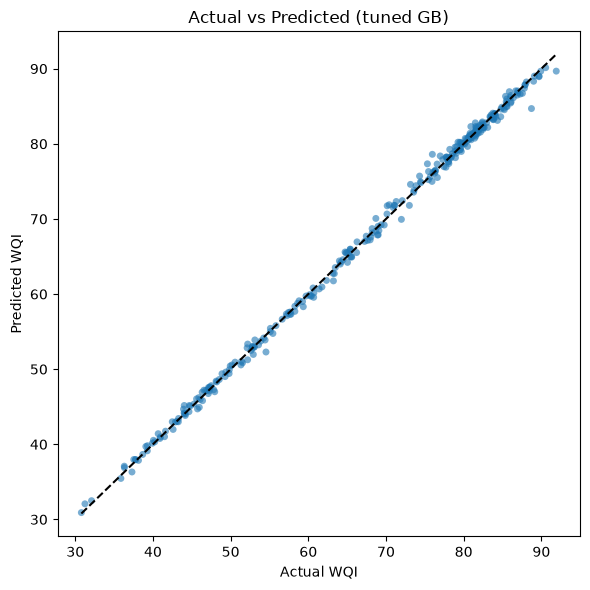

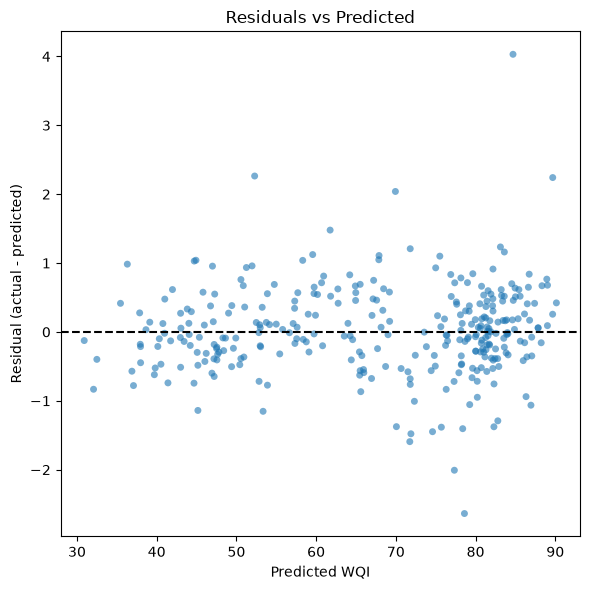

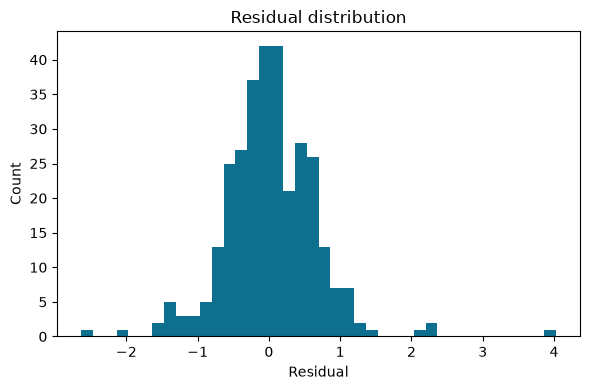

Residual: mean 0.0260, std 0.6499, MAE 0.4690, max|resid| 4.0311

Performance across actual-WQI quintiles:
                  count       MAE  mean_signed_err      RMSE
bin                                                         
(30.782, 49.364]     63  0.385078        -0.093403  0.475213
(49.364, 65.01]      63  0.443956         0.168022  0.599171
(65.01, 77.952]      63  0.670129        -0.156932  0.855128
(77.952, 81.927]     63  0.359709        -0.075860  0.474705
(81.927, 91.918]     63  0.485985         0.288248  0.757450


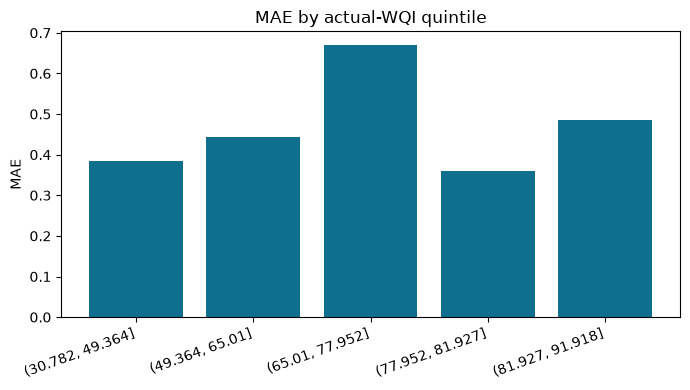


Tuned-GB feature importance:
B.O.D. (mg/l)                       0.955791
PH                                  0.025199
D.O. (mg/l)                         0.008624
NITRATENAN N+ NITRITENANN (mg/l)    0.007993
FECAL COLIFORM (MPN/100ml)          0.001286
TOTAL COLIFORM (MPN/100ml)Mean      0.001012
CONDUCTIVITY (µmhos/cm)             0.000094


In [6]:
# ============================================================
# ERROR ANALYSIS - continuous WAWQI (no rating-band edge analysis, which
# applied only to the old discretised index).
# ============================================================
resid = y_test.values - y_pred

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6, edgecolors="none", s=25)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "--", color="k")
plt.xlabel("Actual WQI"); plt.ylabel("Predicted WQI")
plt.title("Actual vs Predicted (tuned GB)")
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 6))
plt.axhline(0, color="k", ls="--")
plt.scatter(y_pred, resid, alpha=0.6, edgecolors="none", s=25)
plt.xlabel("Predicted WQI"); plt.ylabel("Residual (actual - predicted)")
plt.title("Residuals vs Predicted")
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 4))
plt.hist(resid, bins=40, color="#0f6f8f")
plt.xlabel("Residual"); plt.ylabel("Count"); plt.title("Residual distribution")
plt.tight_layout(); plt.show()
print("Residual: mean %.4f, std %.4f, MAE %.4f, max|resid| %.4f"
      % (resid.mean(), resid.std(), np.mean(np.abs(resid)), np.max(np.abs(resid))))

tmp = pd.DataFrame({"actual": y_test.values, "pred": y_pred})
tmp["resid"] = tmp["actual"] - tmp["pred"]
tmp["abs_err"] = tmp["resid"].abs()
tmp["sq_err"] = tmp["resid"] ** 2
tmp["bin"] = pd.qcut(tmp["actual"], q=5, duplicates="drop")
bin_table = tmp.groupby("bin", observed=True).agg(
    count=("actual", "size"), MAE=("abs_err", "mean"),
    mse=("sq_err", "mean"), mean_signed_err=("resid", "mean"))
bin_table["RMSE"] = np.sqrt(bin_table["mse"])
bin_table = bin_table.drop(columns="mse")
print("\nPerformance across actual-WQI quintiles:")
print(bin_table.to_string())

plt.figure(figsize=(7, 4))
plt.bar(range(len(bin_table)), bin_table["MAE"].values, color="#0f6f8f")
plt.xticks(range(len(bin_table)), [str(i) for i in bin_table.index], rotation=20, ha="right")
plt.ylabel("MAE"); plt.title("MAE by actual-WQI quintile")
plt.tight_layout(); plt.show()

imp = pd.Series(best_model.feature_importances_, index=FEATURES).sort_values(ascending=False)
print("\nTuned-GB feature importance:")
print(imp.to_string())

In [7]:
# ============================================================
# STACKING EXPERIMENT - PRE-REGISTERED DECISION RULE (fixed BEFORE running)
# ============================================================
# Adopt stacking ONLY if BOTH hold:
#   (a) test RMSE improves over tuned GB by >= 5% relative, AND
#   (b) CV R2 mean gain over tuned GB exceeds the tuned-GB CV R2 std.
# The deployed model is NOT changed by this notebook regardless of the outcome.

stack = StackingRegressor(
    estimators=[
        ("dt", DecisionTreeRegressor(random_state=RANDOM_STATE)),
        ("rf", RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE)),
        ("gb", best_model),
    ],
    final_estimator=Ridge(),
    cv=cv,
    n_jobs=-1,
)
stack.fit(X_train, y_train)

stack_test = score(y_test, stack.predict(X_test))
stack_cv = cv_metrics(stack, "Stacking", n_jobs=1)

rmse_gain = (tuned_test["RMSE"] - stack_test["RMSE"]) / tuned_test["RMSE"]
cv_r2_gain = stack_cv["CV R2"] - tuned_cv["CV R2"]

results_df = pd.concat([results_df, pd.DataFrame([{
    "Model": "Stacking (DT+RF+GBtuned / Ridge)", **stack_cv,
    "Test MAE": stack_test["MAE"], "Test RMSE": stack_test["RMSE"], "Test R2": stack_test["R2"],
    "Skill (1-RMSE/RMSE_base)": 1 - stack_test["RMSE"] / baseline_rmse,
}])], ignore_index=True)
print("Full comparison (single held-out test set):")
print(results_df.to_string(index=False))

print("\nStacking decision (pre-registered):")
print("  test RMSE gain vs tuned GB : %.2f%%  (threshold 5.00%%)" % (rmse_gain * 100))
print("  CV R2 gain vs tuned GB     : %.5f  (tuned-GB CV R2 std: %.5f)"
      % (cv_r2_gain, tuned_cv["CV R2 std"]))
adopt = (rmse_gain >= 0.05) and (cv_r2_gain > tuned_cv["CV R2 std"])
print("  => ADOPT stacking:", bool(adopt))

Full comparison (single held-out test set):
                           Model    CV MAE   CV RMSE  CV RMSE std     CV R2  CV R2 std  Test MAE  Test RMSE   Test R2  Skill (1-RMSE/RMSE_base)
           Mean baseline (Dummy) 13.709159 15.677800     0.345972 -0.005804   0.004702 14.045096  16.004612 -0.001396                  0.000000
               Linear Regression 13.159291 31.815723    24.085335 -5.373845   8.281299 12.079783  14.528193  0.174839                  0.092250
                   Decision Tree  1.479441  2.131098     0.184846  0.981148   0.003706  1.210802   1.713308  0.988524                  0.892949
                   Random Forest  0.995031  1.476058     0.109693  0.990982   0.001636  0.853020   1.250820  0.993883                  0.921846
     Gradient Boosting (untuned)  0.645608  0.940152     0.091497  0.996340   0.000737  0.572678   0.758222  0.997752                  0.952625
       Gradient Boosting (tuned)  0.551362  0.819252     0.060082  0.997235   0.000423  0.46

## Interpretation

**The WAWQI target is computed deterministically from the exact seven inputs
the model receives** (proved in the validity gate: zero unique input vectors map
to more than one WQI). The task is therefore **closed-form index approximation,
not independent prediction of real-world water quality.** A model can at best
*recover* the Brown formula; it **cannot be claimed to outperform the WQI
equation** (the equation *is* the ground-truth label; perfect recovery is
R-squared = 1).

What these experiments legitimately support:

1. **Recovery skill vs a trivial baseline** (mean-baseline reference; the tuned
   GB `Skill` column measures how much of the index it reproduces).
2. **Where residual error lives** (quintile table across the target range).
   Unlike the previous discretised index, the WAWQI is continuous, so the old
   rating-band-edge analysis was removed.
3. **SHAP / importance consistency** with the index's own inverse-standard
   weighting (BOD and DO carry the largest unit weights), reported as agreement
   with the index definition, not as discovery of hidden drivers.
4. **A rigorous, re-runnable protocol** (frozen split, shared CV folds, tuning
   isolated from test, pre-registered stacking rule).

Because the target is deterministic and smooth, the stacked ensemble is expected
to give little or no gain over the tuned GB; the deployed model is **not**
changed by this notebook regardless of the result.

In [8]:
# ============================================================
# RUN MANIFEST
# ============================================================
print("=" * 60)
print("RUN MANIFEST")
print("=" * 60)
print("N samples           :", len(wqi_df))
print("Features (n)        :", len(FEATURES))
print("Feature order       :", FEATURES)
print("Train / Test        :", len(X_train), "/", len(X_test))
print("random_state        :", RANDOM_STATE)
print("sklearn / shap      :", sklearn.__version__, "/", shap.__version__)
print("Index scale         : Brown WAWQI, 0-100, LOWER = BETTER")
print("Target observed min/max: %.4f / %.4f" % (wqi_df["WQI"].min(), wqi_df["WQI"].max()))

print("\nHeadline test metrics (this run; single held-out test set):")
for _, r in results_df.iterrows():
    print("  %-34s MAE %.4f  RMSE %.4f  R2 %.4f"
          % (r["Model"], r["Test MAE"], r["Test RMSE"], r["Test R2"]))

RUN MANIFEST
N samples           : 1571
Features (n)        : 7
Feature order       : ['D.O. (mg/l)', 'PH', 'CONDUCTIVITY (µmhos/cm)', 'B.O.D. (mg/l)', 'NITRATENAN N+ NITRITENANN (mg/l)', 'FECAL COLIFORM (MPN/100ml)', 'TOTAL COLIFORM (MPN/100ml)Mean']
Train / Test        : 1256 / 315
random_state        : 42
sklearn / shap      : 1.9.0 / 0.52.0
Index scale         : Brown WAWQI, 0-100, LOWER = BETTER
Target observed min/max: 22.3865 / 92.2754

Headline test metrics (this run; single held-out test set):
  Mean baseline (Dummy)              MAE 14.0451  RMSE 16.0046  R2 -0.0014
  Linear Regression                  MAE 12.0798  RMSE 14.5282  R2 0.1748
  Decision Tree                      MAE 1.2108  RMSE 1.7133  R2 0.9885
  Random Forest                      MAE 0.8530  RMSE 1.2508  R2 0.9939
  Gradient Boosting (untuned)        MAE 0.5727  RMSE 0.7582  R2 0.9978
  Gradient Boosting (tuned)          MAE 0.4690  RMSE 0.6504  R2 0.9983
  Stacking (DT+RF+GBtuned / Ridge)   MAE 0.4876  RMSE 0